# Example 13: Phase transition

In this example, we will use KAN to learn phase transitions in data. Phase transition is an important concept in science. We consider a toy example $f(x_1,x_2,x_3)$ is 1 if $g(x_1,x_2,x_3)>0$, and is 0 if $g(x_1,x_2,x_3)<0$. $g(x_1,x_2,x_3)={\rm sin}(\pi x_1)+{\rm cos}(\pi x_2)+{\rm tan}(\frac{\pi}{2}x_3)$.

Intialize model and create dataset

In [1]:
import torch
from xkan import KANNetwork, create_dataset, fit
from xkan.symbolic import fix_symbolic
from xkan.viz import plot

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
print(device)

model = KANNetwork([3, 1, 1], grid=3, k=3, device=device)

# create dataset
f = lambda x: (torch.sin(torch.pi*x[:,[0]]) + torch.cos(torch.pi*x[:,[1]]) + torch.tan(torch.pi/2*x[:,[2]]) > 0).float()
train, test = create_dataset(f, n_var=3, device=device)

cuda


In [2]:
torch.mean(train['y'])

tensor(0.5060, device='cuda:0')

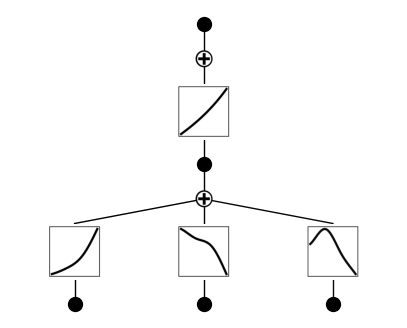

In [3]:
plot(model, train['x'], beta=10);

In [4]:
# set the last activation to be tanh
fix_symbolic(model, 1, 0, 0, 'tanh', fit=False)

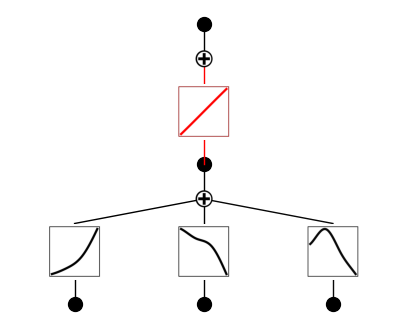

In [5]:
plot(model, train['x'], beta=10);

In [6]:
history = fit(model, train, test, steps=50)
print('train RMSE', history['train/y'][-1] ** 0.5, 'test RMSE', history['val/y'][-1] ** 0.5)

train RMSE 0.07712231869940331 test RMSE 0.11134245428926137


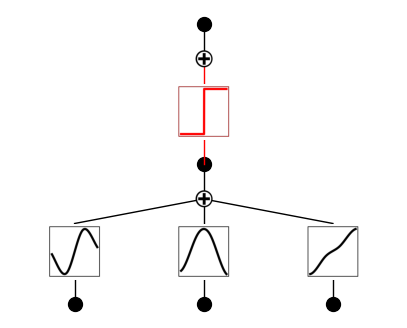

In [7]:
plot(model, train['x'], beta=10);